# 7장. 그래프로 데이터의 이야기를 보여주기

이 노트북은 `book/chapters/ch07_visualization.md` 강의안을 초보자가 그대로 따라 하며 이해할 수 있도록 구성한 실습 자료입니다.

이번 장의 핵심은 그래프를 많이 그리는 것이 아니라, **분석 질문에 맞는 그래프를 고르고, 그래프가 보여주는 것과 보여주지 않는 것을 구분하는 것**입니다.


## 0. 이 노트북 사용 방법

아래 셀을 위에서부터 차례대로 실행하세요.

- 이 노트북은 5장에서 만든 `data/processed/*_clean.csv` 파일을 사용합니다.
- 전처리 파일이 없다면 먼저 `python scripts/preprocess_data.py`를 실행하세요.
- 그래프 파일은 `reports/figures/` 폴더에 저장합니다.
- 그래프 해석에서는 관찰과 원인 가설을 반드시 구분합니다.


## 1. 시각화는 분석 질문에서 시작된다

좋은 시각화는 그래프 종류를 많이 아는 데서 시작하지 않습니다. 먼저 어떤 질문에 답하려는지 정해야 합니다.

| 분석 목적 | 적합한 그래프 | 예시 질문 |
|---|---|---|
| 범주별 크기 비교 | 막대그래프 | 카테고리별 매출은 어떻게 다른가? |
| 시간 흐름 확인 | 선 그래프 | 월별 매출은 어떻게 변하는가? |
| 값의 분포 확인 | 히스토그램 | 상품 가격은 어떤 범위에 몰려 있는가? |
| 두 변수 관계 확인 | 산점도 | 가격과 판매 수량은 관계가 있는가? |
| 상위 항목 비교 | 가로 막대그래프 | 구매 금액 상위 고객은 누구인가? |
| 비율 비교 | 막대그래프 또는 파이 차트 | 주문 상태별 비중은 어떻게 되는가? |


## 2. 이번 장에서 만들 그래프

이번 장에서는 6장 EDA에서 만든 질문을 그래프로 표현합니다.

| 시각화 질문 | 사용할 데이터 | 그래프 |
|---|---|---|
| 카테고리별 매출은 어떻게 다른가? | `category_sales` | 막대그래프 |
| 월별 매출은 어떻게 변하는가? | `monthly_sales` | 선 그래프 |
| 상품 가격은 어떤 구간에 몰려 있는가? | `products` | 히스토그램 |
| 상품 가격과 판매 수량은 관계가 있는가? | `product_sales` | 산점도 |
| 구매 금액 상위 고객은 누구인가? | `customer_sales` | 가로 막대그래프 |
| 주문 상태별 주문 수는 어떻게 다른가? | `orders` | 막대그래프 |


## 3. 패키지와 경로 설정

노트북이 `notebooks/` 폴더 안에서 실행되는 경우와 프로젝트 루트에서 실행되는 경우를 모두 고려해 경로를 설정합니다.


In [2]:
from pathlib import Path
import sys

import pandas as pd
import matplotlib.pyplot as plt

CURRENT_DIR = Path.cwd()

if CURRENT_DIR.name == 'notebooks':
    PROJECT_ROOT = CURRENT_DIR.parent
else:
    PROJECT_ROOT = CURRENT_DIR

PROCESSED_DIR = PROJECT_ROOT / 'data' / 'processed'
REPORT_DIR = PROJECT_ROOT / 'reports'
FIGURE_DIR = REPORT_DIR / 'figures'

REPORT_DIR.mkdir(exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print('현재 실행 위치:', CURRENT_DIR)
print('프로젝트 루트:', PROJECT_ROOT)
print('전처리 데이터 폴더:', PROCESSED_DIR)
print('그래프 저장 폴더:', FIGURE_DIR)


현재 실행 위치: c:\dev\llm-data-analysis-course\notebooks
프로젝트 루트: c:\dev\llm-data-analysis-course
전처리 데이터 폴더: c:\dev\llm-data-analysis-course\data\processed
그래프 저장 폴더: c:\dev\llm-data-analysis-course\reports\figures


## 4. 한글 폰트 설정

matplotlib에서 한글 제목이나 축 이름을 사용하면 글자가 깨질 수 있습니다. Windows 환경에서는 보통 `Malgun Gothic`을 사용합니다. Mac은 `AppleGothic`, Linux는 `NanumGothic`을 사용할 수 있습니다.


In [3]:
plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False

print('matplotlib 한글 폰트 설정 완료')


matplotlib 한글 폰트 설정 완료


## 5. 전처리 데이터 불러오기

7장은 5장에서 저장한 전처리 데이터를 사용합니다. 파일이 없다면 터미널에서 `python scripts/preprocess_data.py`를 먼저 실행하세요.


In [4]:
required_files = [
    PROCESSED_DIR / 'customers_clean.csv',
    PROCESSED_DIR / 'products_clean.csv',
    PROCESSED_DIR / 'orders_clean.csv',
    PROCESSED_DIR / 'order_items_clean.csv',
]

missing_files = [path for path in required_files if not path.exists()]
if missing_files:
    for path in missing_files:
        print('누락 파일:', path)
    raise FileNotFoundError('전처리 파일이 없습니다. 먼저 python scripts/preprocess_data.py 를 실행하세요.')

customers = pd.read_csv(PROCESSED_DIR / 'customers_clean.csv')
products = pd.read_csv(PROCESSED_DIR / 'products_clean.csv')
orders = pd.read_csv(PROCESSED_DIR / 'orders_clean.csv')
order_items = pd.read_csv(PROCESSED_DIR / 'order_items_clean.csv')

print('전처리 데이터 불러오기 완료')


전처리 데이터 불러오기 완료


In [5]:
orders['order_date'] = pd.to_datetime(orders['order_date'], errors='coerce')

if 'order_month' not in orders.columns:
    orders['order_month'] = orders['order_date'].dt.to_period('M').astype(str)

if 'line_total' not in order_items.columns:
    order_items['line_total'] = order_items['quantity'] * order_items['unit_price']

print('customers:', customers.shape)
print('products:', products.shape)
print('orders:', orders.shape)
print('order_items:', order_items.shape)


customers: (150, 6)
products: (100, 4)
orders: (300, 7)
order_items: (764, 6)


## 6. 시각화를 위한 집계 데이터 만들기

그래프를 그리기 전에 필요한 집계표를 만듭니다. 대부분의 시각화는 원본 데이터를 바로 그리기보다, 질문에 맞게 요약한 표를 만든 뒤 그립니다.


In [6]:
sales_items = order_items.merge(
    products,
    on='product_id',
    how='left',
)

print('병합 전 order_items:', order_items.shape)
print('병합 후 sales_items:', sales_items.shape)
print('카테고리 누락:', sales_items['category'].isna().sum())

sales_items.head()


병합 전 order_items: (764, 6)
병합 후 sales_items: (764, 9)
카테고리 누락: 0


,order_item_id,order_id,product_id,quantity,unit_price,line_total,product_name,category,price
0,1,1,100,3,102000,306000,도서 상품 100,도서,102000
1,2,1,87,5,25000,125000,도서 상품 087,도서,25000
2,3,1,7,3,142000,426000,도서 상품 007,도서,142000
3,4,1,9,3,193000,579000,스포츠 상품 009,스포츠,193000
4,5,2,72,4,189000,756000,뷰티 상품 072,뷰티,189000


In [7]:
category_sales = (
    sales_items
    .groupby('category', as_index=False)
    .agg(
        total_quantity=('quantity', 'sum'),
        total_sales=('line_total', 'sum'),
    )
    .sort_values('total_sales', ascending=False)
)

category_sales['sales_ratio'] = (
    category_sales['total_sales'] / category_sales['total_sales'].sum() * 100
).round(2)

category_sales


,category,total_quantity,total_sales,sales_ratio
3,스포츠,468,50174000,19.63
1,뷰티,376,47551000,18.60
5,전자기기,401,41003000,16.04
2,생활용품,390,34839000,13.63
4,식품,240,33597000,13.14
0,도서,238,24645000,9.64
6,패션,220,23801000,9.31


In [8]:
order_sales = order_items.merge(
    orders,
    on='order_id',
    how='left',
)

order_sales['order_date'] = pd.to_datetime(order_sales['order_date'], errors='coerce')
order_sales['order_month'] = order_sales['order_date'].dt.to_period('M').astype(str)

monthly_sales = (
    order_sales
    .groupby('order_month', as_index=False)
    .agg(
        total_sales=('line_total', 'sum'),
        order_count=('order_id', 'nunique'),
    )
    .sort_values('order_month')
)

monthly_sales


,order_month,total_sales,order_count
0,2025-09,5640000,10
1,2025-10,25451000,27
2,2025-11,17912000,21
3,2025-12,32113000,35
4,2026-01,28202000,29
5,2026-02,13990000,16
6,2026-03,24367000,34
7,2026-04,24446000,28
8,2026-05,24775000,27
9,2026-06,19882000,26


In [9]:
product_sales = (
    sales_items
    .groupby(['product_id', 'product_name', 'category', 'price'], as_index=False)
    .agg(
        total_quantity=('quantity', 'sum'),
        total_sales=('line_total', 'sum'),
    )
    .sort_values('total_sales', ascending=False)
)

product_sales.head()


,product_id,product_name,category,price,total_quantity,total_sales
57,58,식품 상품 058,식품,197000,59,11623000
98,99,뷰티 상품 099,뷰티,200000,38,7600000
40,41,스포츠 상품 041,스포츠,163000,42,6846000
71,72,뷰티 상품 072,뷰티,189000,36,6804000
70,71,전자기기 상품 071,전자기기,161000,41,6601000


In [10]:
customer_sales_base = order_sales.merge(
    customers,
    on='customer_id',
    how='left',
)

group_columns = ['customer_id', 'city']
if 'name' in customer_sales_base.columns:
    group_columns = ['customer_id', 'name', 'city']

customer_sales = (
    customer_sales_base
    .groupby(group_columns, as_index=False)
    .agg(
        order_count=('order_id', 'nunique'),
        total_sales=('line_total', 'sum'),
    )
    .sort_values('total_sales', ascending=False)
)

customer_sales['avg_order_value'] = (
    customer_sales['total_sales'] / customer_sales['order_count']
).round(0)

customer_sales.head()


,customer_id,name,city,order_count,total_sales,avg_order_value
79,102,이진호,고양,5,5977000,1195400.0
93,117,김지원,성남,6,5552000,925333.0
67,83,전은경,수원,5,4951000,990200.0
118,142,하서연,서울,3,4862000,1620667.0
34,40,박예준,서울,5,4857000,971400.0


In [11]:
order_status = orders['order_status'].value_counts(dropna=False).reset_index()
order_status.columns = ['order_status', 'order_count']
order_status


,order_status,order_count
0,completed,184
1,cancelled,64
2,refunded,52


## 7. 카테고리별 매출 막대그래프

카테고리별 매출은 범주별 크기 비교이므로 막대그래프가 적합합니다. 그래프는 화면에 표시하고 동시에 PNG 파일로 저장합니다.


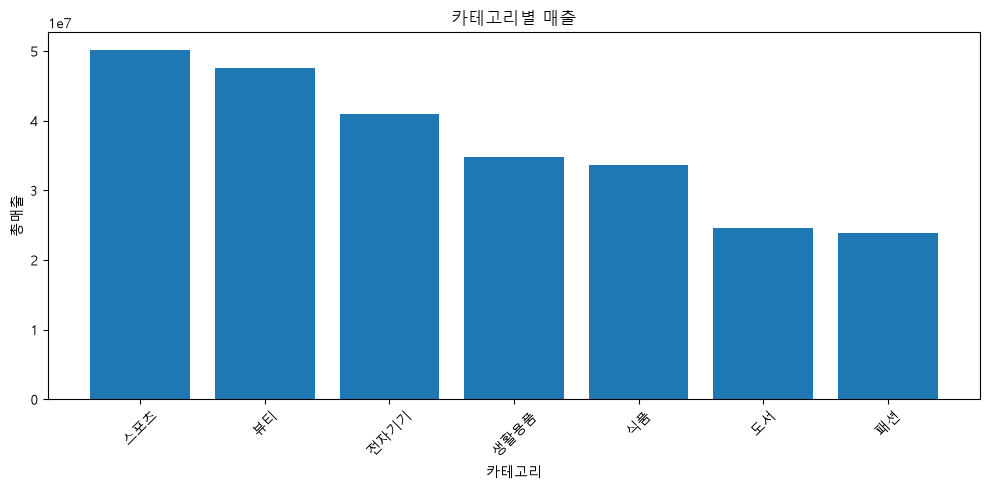

In [12]:
plt.figure(figsize=(10, 5))
plt.bar(category_sales['category'], category_sales['total_sales'])
plt.title('카테고리별 매출')
plt.xlabel('카테고리')
plt.ylabel('총매출')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(FIGURE_DIR / 'ch07_category_sales_bar.png', dpi=150, bbox_inches='tight')
plt.show()


해석 예시:

> 관찰: 카테고리별 매출 크기가 서로 다르게 나타납니다.
> 가설: 매출 차이는 판매 수량 또는 평균 단가 차이에서 비롯되었을 수 있습니다.
> 추가 분석: 카테고리별 판매 수량과 평균 단가를 함께 확인해야 합니다.


### assignment step2 그래프

completed 주문 상세 행 수: 474
카테고리 누락: 0
completed 원본 합계: 148,990,000
카테고리 합계 = 원본 합계: True


,category,total_quantity,total_sales,sales_ratio
0,스포츠,295,31743000,21.31
1,전자기기,259,26400000,17.72
2,생활용품,272,23915000,16.05
3,뷰티,223,23383000,15.69
4,식품,133,16573000,11.12
5,도서,149,16389000,11.00
6,패션,111,10587000,7.11


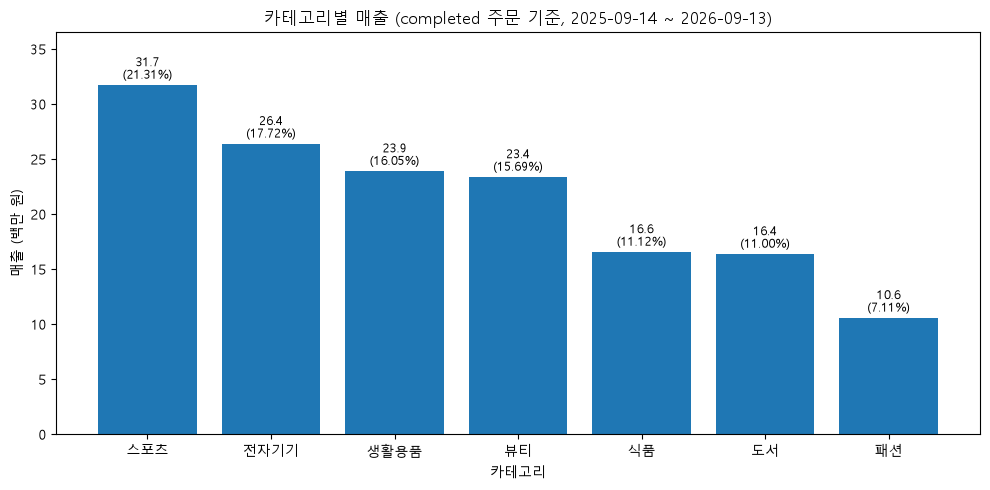

막대 높이 = 집계표 total_sales: True
y축 시작값: 0.0


In [13]:
# 대표 그래프 1. completed 주문 기준 카테고리별 매출 막대그래프
from matplotlib.ticker import FuncFormatter

completed_sales_items = (
    order_sales[order_sales['order_status'] == 'completed']
    .merge(products[['product_id', 'category']], on='product_id', how='left')
)

completed_category_sales = (
    completed_sales_items
    .groupby('category', as_index=False)
    .agg(
        total_quantity=('quantity', 'sum'),
        total_sales=('line_total', 'sum'),
    )
    .sort_values('total_sales', ascending=False)
    .reset_index(drop=True)
)
completed_category_sales['sales_ratio'] = (
    completed_category_sales['total_sales'] / completed_category_sales['total_sales'].sum() * 100
).round(2)

completed_total = completed_sales_items['line_total'].sum()
period = f"{orders['order_date'].min():%Y-%m-%d} ~ {orders['order_date'].max():%Y-%m-%d}"

print('completed 주문 상세 행 수:', len(completed_sales_items))
print('카테고리 누락:', completed_sales_items['category'].isna().sum())
print('completed 원본 합계:', f'{completed_total:,}')
print('카테고리 합계 = 원본 합계:', completed_category_sales['total_sales'].sum() == completed_total)
display(completed_category_sales)

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(completed_category_sales['category'], completed_category_sales['total_sales'])
label_offset = completed_category_sales['total_sales'].max() * 0.01

for bar, sales, ratio in zip(bars, completed_category_sales['total_sales'], completed_category_sales['sales_ratio']):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + label_offset,
        f'{sales / 1e6:.1f}\n({ratio:.2f}%)',
        ha='center',
        va='bottom',
        fontsize=9,
    )

ax.set_title(f'카테고리별 매출 (completed 주문 기준, {period})')
ax.set_xlabel('카테고리')
ax.set_ylabel('매출 (백만 원)')
ax.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f'{x / 1e6:,.0f}'))
ax.set_ylim(0, completed_category_sales['total_sales'].max() * 1.15)
plt.tight_layout()
plt.savefig(FIGURE_DIR / 'ch07_completed_category_sales_bar.png', dpi=150, bbox_inches='tight')
plt.show()

# 그래프 값과 집계표 값 교차 확인 (STEP 6)
bar_heights = [bar.get_height() for bar in bars]
print('막대 높이 = 집계표 total_sales:', bar_heights == completed_category_sales['total_sales'].tolist())
print('y축 시작값:', ax.get_ylim()[0])

## 8. 월별 매출 선 그래프

월별 매출은 시간 흐름을 보는 문제이므로 선 그래프가 적합합니다. x축 순서가 월 순서대로 정렬되어 있어야 합니다.


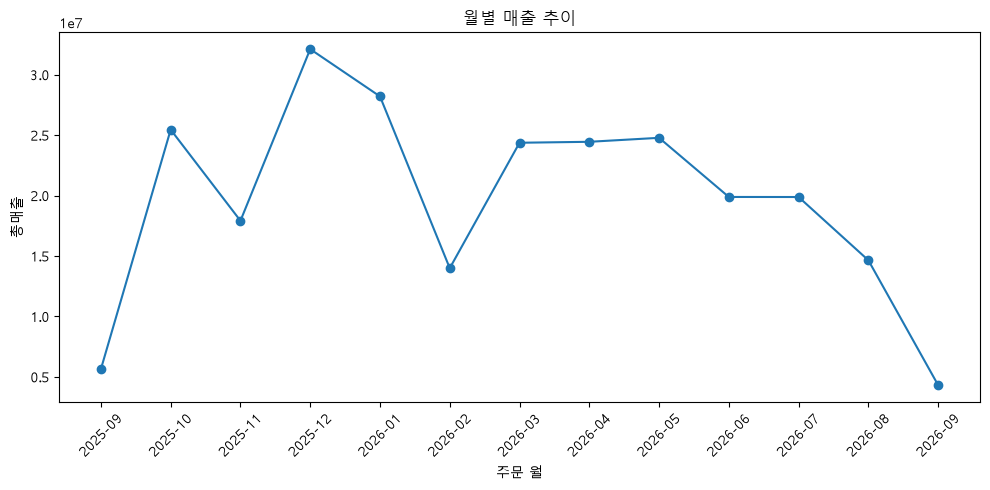

In [14]:
plt.figure(figsize=(10, 5))
plt.plot(monthly_sales['order_month'], monthly_sales['total_sales'], marker='o')
plt.title('월별 매출 추이')
plt.xlabel('주문 월')
plt.ylabel('총매출')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(FIGURE_DIR / 'ch07_monthly_sales_line.png', dpi=150, bbox_inches='tight')
plt.show()


월별 매출이 증가하거나 감소해도 그 원인을 바로 단정하면 안 됩니다. 주문 수, 평균 주문 금액, 프로모션 여부, 특정 카테고리 매출 변화를 추가로 확인해야 합니다.


### assignment step3 그래프

월 수: 13
월 순서 정렬: True
누락된 월(completed 주문 0건): []
일부 기간만 포함된 달: ['2025-09', '2026-09']
월별 합계: 148,990,000 / 원본 합계: 148,990,000
월별 합계 = 원본 합계: True


,order_month,total_sales,order_count,avg_order_value,observed_days,days_in_month,is_partial,daily_avg_sales
0,2025-09,2650000,5,530000.0,17,30,True,155882.0
1,2025-10,16970000,19,893158.0,31,31,False,547419.0
2,2025-11,11021000,13,847769.0,30,30,False,367367.0
3,2025-12,22314000,24,929750.0,31,31,False,719806.0
4,2026-01,13303000,16,831438.0,31,31,False,429129.0
5,2026-02,5318000,7,759714.0,28,28,False,189929.0
6,2026-03,17529000,24,730375.0,31,31,False,565452.0
7,2026-04,11832000,17,696000.0,30,30,False,394400.0
8,2026-05,16345000,18,908056.0,31,31,False,527258.0
9,2026-06,14070000,18,781667.0,30,30,False,469000.0


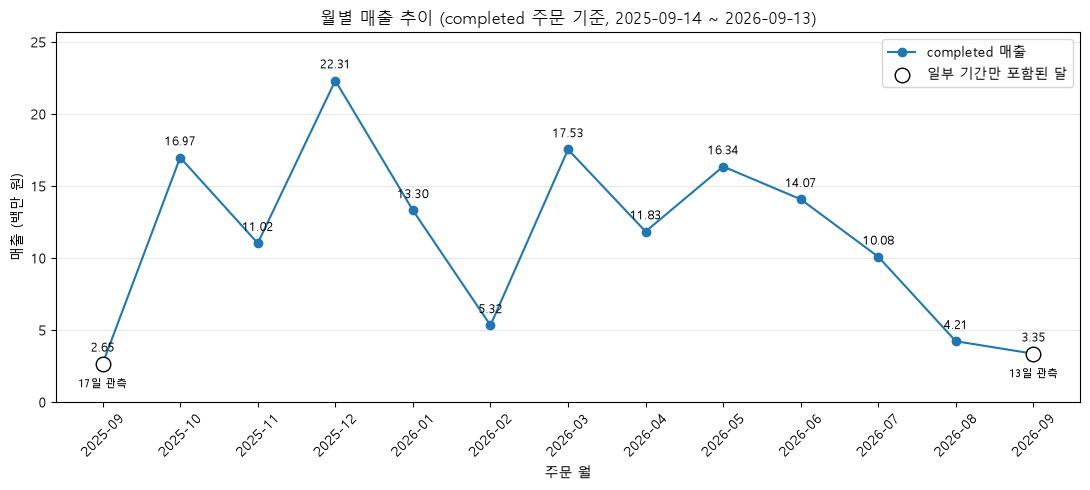

선 그래프 값 = 집계표 total_sales: True
x축 순서 = 집계표 월 순서: True
y축 시작값: 0.0


In [15]:
# 대표 그래프 2. completed 주문 기준 월별 매출 선그래프
from matplotlib.ticker import FuncFormatter

completed_order_sales = order_sales[order_sales['order_status'] == 'completed']

completed_monthly_sales = (
    completed_order_sales
    .groupby('order_month', as_index=False)
    .agg(
        total_sales=('line_total', 'sum'),
        order_count=('order_id', 'nunique'),
    )
)

# 누락된 월 확인: 첫 주문 월부터 마지막 주문 월까지 모든 월을 채운 뒤 0인 달을 찾습니다.
first_date = orders['order_date'].min().normalize()
last_date = orders['order_date'].max().normalize()
all_months = pd.period_range(first_date, last_date, freq='M').astype(str)

completed_monthly_sales = (
    completed_monthly_sales
    .set_index('order_month')
    .reindex(all_months, fill_value=0)
    .rename_axis('order_month')
    .reset_index()
)
missing_months = completed_monthly_sales.loc[
    completed_monthly_sales['order_count'] == 0, 'order_month'
].tolist()

completed_monthly_sales['avg_order_value'] = (
    completed_monthly_sales['total_sales']
    / completed_monthly_sales['order_count'].where(completed_monthly_sales['order_count'] > 0)
).round(0)

# 일부 기간만 포함된 달 확인: 데이터 기간(첫 주문일 ~ 마지막 주문일) 안에 든 일수
month_start = pd.to_datetime(completed_monthly_sales['order_month'])
month_end = month_start + pd.offsets.MonthEnd(0)
completed_monthly_sales['observed_days'] = (
    month_end.clip(upper=last_date) - month_start.clip(lower=first_date)
).dt.days + 1
completed_monthly_sales['days_in_month'] = month_end.dt.day
completed_monthly_sales['is_partial'] = (
    completed_monthly_sales['observed_days'] < completed_monthly_sales['days_in_month']
)
completed_monthly_sales['daily_avg_sales'] = (
    completed_monthly_sales['total_sales'] / completed_monthly_sales['observed_days']
).round(0)

period = f'{first_date:%Y-%m-%d} ~ {last_date:%Y-%m-%d}'

print('월 수:', len(completed_monthly_sales))
print('월 순서 정렬:', completed_monthly_sales['order_month'].is_monotonic_increasing)
print('누락된 월(completed 주문 0건):', missing_months)
print('일부 기간만 포함된 달:', completed_monthly_sales.loc[completed_monthly_sales['is_partial'], 'order_month'].tolist())
print('월별 합계:', f"{completed_monthly_sales['total_sales'].sum():,}",
      '/ 원본 합계:', f"{completed_order_sales['line_total'].sum():,}")
print('월별 합계 = 원본 합계:', completed_monthly_sales['total_sales'].sum() == completed_order_sales['line_total'].sum())
display(completed_monthly_sales)

fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(
    completed_monthly_sales['order_month'],
    completed_monthly_sales['total_sales'],
    marker='o',
    label='completed 매출',
)

partial_months = completed_monthly_sales[completed_monthly_sales['is_partial']]
ax.scatter(
    partial_months['order_month'],
    partial_months['total_sales'],
    s=110,
    facecolors='white',
    edgecolors='black',
    zorder=3,
    label='일부 기간만 포함된 달',
)

label_offset = completed_monthly_sales['total_sales'].max() * 0.03
for month, sales in zip(completed_monthly_sales['order_month'], completed_monthly_sales['total_sales']):
    ax.text(month, sales + label_offset, f'{sales / 1e6:.2f}', ha='center', va='bottom', fontsize=9)

for month, sales, days in zip(partial_months['order_month'], partial_months['total_sales'], partial_months['observed_days']):
    ax.text(month, sales - label_offset * 1.5, f'{days}일 관측', ha='center', va='top', fontsize=8)

ax.set_title(f'월별 매출 추이 (completed 주문 기준, {period})')
ax.set_xlabel('주문 월')
ax.set_ylabel('매출 (백만 원)')
ax.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f'{x / 1e6:,.0f}'))
ax.set_ylim(0, completed_monthly_sales['total_sales'].max() * 1.15)
ax.grid(axis='y', alpha=0.3)
ax.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(FIGURE_DIR / 'ch07_completed_monthly_sales_line.png', dpi=150, bbox_inches='tight')
plt.show()

# 그래프 값과 집계표 값 교차 확인 (STEP 6)
line_values = list(ax.lines[0].get_ydata())
print('선 그래프 값 = 집계표 total_sales:', line_values == completed_monthly_sales['total_sales'].tolist())
print('x축 순서 = 집계표 월 순서:', list(ax.lines[0].get_xdata()) == completed_monthly_sales['order_month'].tolist())
print('y축 시작값:', ax.get_ylim()[0])

## 9. 상품 가격 분포 히스토그램

히스토그램은 숫자형 데이터가 어느 구간에 많이 몰려 있는지 보여줍니다. 상품 가격 분포를 보면 저가/중가/고가 상품이 어떻게 분포하는지 확인할 수 있습니다.


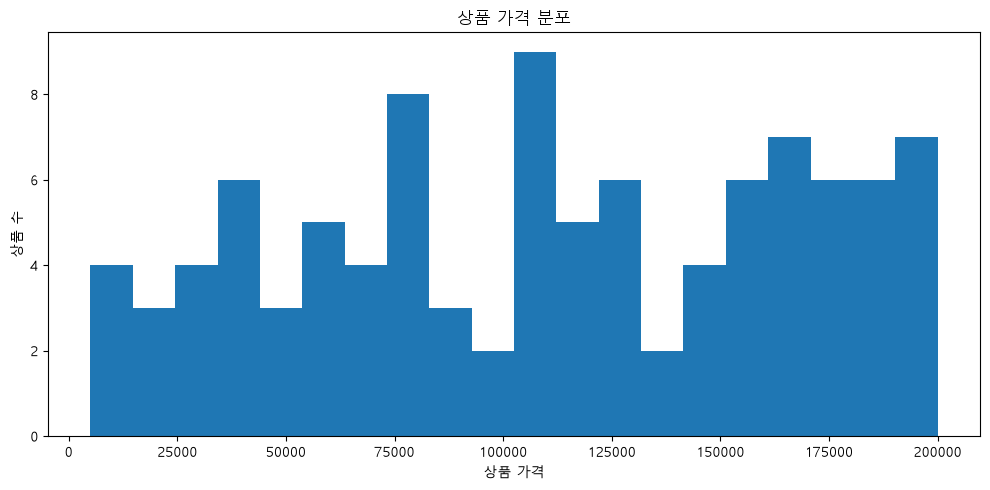

In [16]:
plt.figure(figsize=(10, 5))
plt.hist(products['price'], bins=20)
plt.title('상품 가격 분포')
plt.xlabel('상품 가격')
plt.ylabel('상품 수')
plt.tight_layout()
plt.savefig(FIGURE_DIR / 'ch07_product_price_hist.png', dpi=150, bbox_inches='tight')
plt.show()


### assignment step4 그래프

상품 수: 100 / 가격 결측: 0 / 0 이하: 0


,count,mean,std,min,25%,50%,75%,max
price,100.0,110040.0,56434.0,5000.0,65750.0,112000.0,161000.0,200000.0


IQR 기준 극단값 경계: -77,125원 미만 또는 303,875원 초과
IQR 기준 극단값 후보 수: 0


,price_from,price_to,product_count
0,0,10000,2
1,10000,20000,2
2,20000,30000,5
3,30000,40000,6
4,40000,50000,4
5,50000,60000,5
6,60000,70000,3
7,70000,80000,7
8,80000,90000,6
9,90000,100000,0


,price_band,product_count
0,5만 원 미만,19
1,5만~10만 원 미만,21
2,10만~15만 원 미만,28
3,15만 원 이상,32


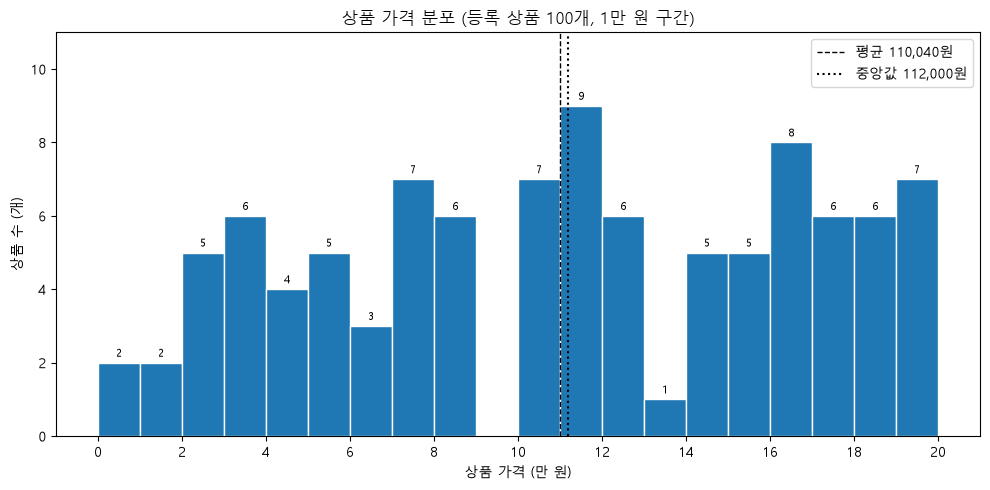

히스토그램 막대 높이 = 구간 집계표: True
구간 합계 = 상품 수: True
5만 원 묶음 합계 = 상품 수: True


In [17]:
# 대표 그래프 3. 상품 가격 분포 히스토그램 (등록 상품 100개 기준, 주문 상태와 무관)
import numpy as np
from matplotlib.ticker import FuncFormatter

price = products['price']

# 1) 기초 통계와 극단값 후보 (IQR 1.5배 기준)
q1, q3 = price.quantile([0.25, 0.75])
iqr = q3 - q1
lower_fence = q1 - 1.5 * iqr
upper_fence = q3 + 1.5 * iqr
outlier_candidates = products[(price < lower_fence) | (price > upper_fence)]

print('상품 수:', len(products), '/ 가격 결측:', price.isna().sum(), '/ 0 이하:', (price <= 0).sum())
display(price.describe().round(0).to_frame('price').T)
print(f'IQR 기준 극단값 경계: {lower_fence:,.0f}원 미만 또는 {upper_fence:,.0f}원 초과')
print('IQR 기준 극단값 후보 수:', len(outlier_candidates))

# 2) 1만 원 구간 집계표 (plt.hist와 같은 규칙: 마지막 구간만 오른쪽 끝 포함)
bin_width = 10_000
bin_edges = np.arange(0, np.ceil(price.max() / bin_width) * bin_width + bin_width, bin_width)
bin_counts, _ = np.histogram(price, bins=bin_edges)
price_bin_table = pd.DataFrame({
    'price_from': bin_edges[:-1].astype(int),
    'price_to': bin_edges[1:].astype(int),
    'product_count': bin_counts,
})
display(price_bin_table)

# 3) 5만 원 단위로 묶은 요약 (중앙 몰림·꼬리 확인용)
band_table = (
    pd.cut(
        price,
        bins=[0, 50_000, 100_000, 150_000, price.max() + 1],
        right=False,
        labels=['5만 원 미만', '5만~10만 원 미만', '10만~15만 원 미만', '15만 원 이상'],
    )
    .value_counts(sort=False)
    .rename_axis('price_band')
    .reset_index(name='product_count')
)
display(band_table)

# 4) 히스토그램
fig, ax = plt.subplots(figsize=(10, 5))
hist_counts, _, patches = ax.hist(price, bins=bin_edges, edgecolor='white')

for patch, count in zip(patches, hist_counts):
    if count > 0:
        ax.text(patch.get_x() + patch.get_width() / 2, count + 0.1, f'{int(count)}',
                ha='center', va='bottom', fontsize=8)

ax.axvline(price.mean(), color='black', linestyle='--', linewidth=1,
           label=f'평균 {price.mean():,.0f}원')
ax.axvline(price.median(), color='black', linestyle=':', linewidth=1.5,
           label=f'중앙값 {price.median():,.0f}원')

ax.set_title(f'상품 가격 분포 (등록 상품 {len(products)}개, 1만 원 구간)')
ax.set_xlabel('상품 가격 (만 원)')
ax.set_ylabel('상품 수 (개)')
ax.set_xticks(bin_edges[::2])
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f'{x / 10_000:,.0f}'))
ax.set_ylim(0, hist_counts.max() + 2)
ax.legend()
plt.tight_layout()
plt.savefig(FIGURE_DIR / 'ch07_product_price_hist_10k.png', dpi=150, bbox_inches='tight')
plt.show()

# 5) 그래프 값과 집계표 값 교차 확인 (STEP 6)
print('히스토그램 막대 높이 = 구간 집계표:', hist_counts.astype(int).tolist() == price_bin_table['product_count'].tolist())
print('구간 합계 = 상품 수:', int(hist_counts.sum()) == len(products))
print('5만 원 묶음 합계 = 상품 수:', band_table['product_count'].sum() == len(products))

## 10. 상품 가격과 판매 수량 산점도

산점도는 두 숫자형 변수의 관계를 탐색할 때 사용합니다. 여기서는 상품 가격과 총 판매 수량 사이의 관계를 확인합니다. 산점도만으로 원인 관계를 단정해서는 안 됩니다.


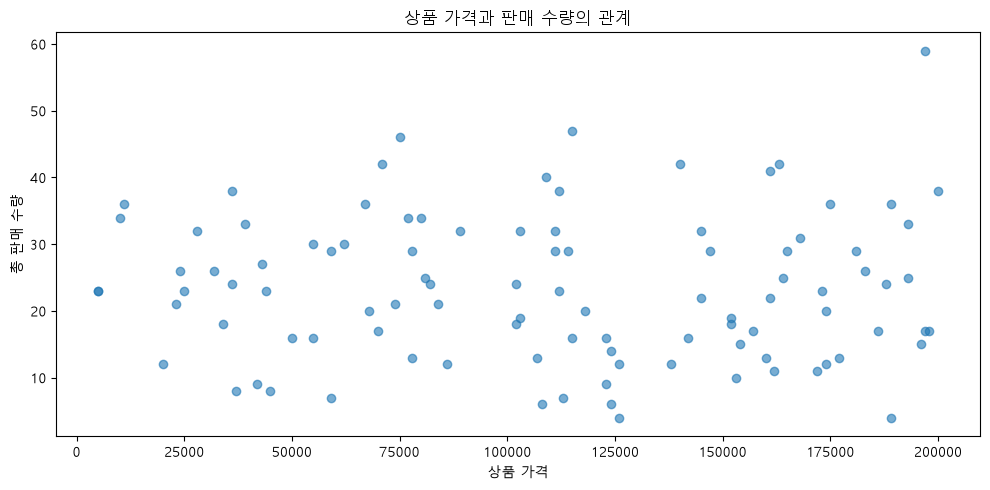

In [18]:
plt.figure(figsize=(10, 5))
plt.scatter(product_sales['price'], product_sales['total_quantity'], alpha=0.6)
plt.title('상품 가격과 판매 수량의 관계')
plt.xlabel('상품 가격')
plt.ylabel('총 판매 수량')
plt.tight_layout()
plt.savefig(FIGURE_DIR / 'ch07_price_quantity_scatter.png', dpi=150, bbox_inches='tight')
plt.show()


## 11. 구매 금액 상위 고객 가로 막대그래프

상위 항목을 비교할 때는 가로 막대그래프가 읽기 좋습니다. 고객명은 개인정보가 될 수 있으므로 보고서에서는 익명화 라벨을 사용하는 것이 좋습니다.


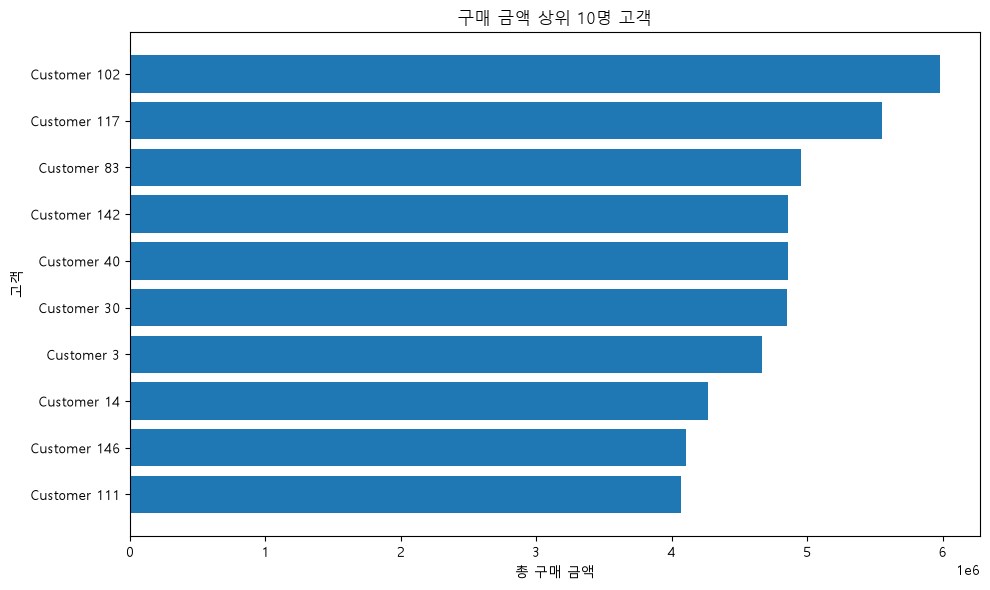

In [19]:
top_customers = customer_sales.head(10).copy()
top_customers['customer_label'] = 'Customer ' + top_customers['customer_id'].astype(str)
top_customers = top_customers.sort_values('total_sales')

plt.figure(figsize=(10, 6))
plt.barh(top_customers['customer_label'], top_customers['total_sales'])
plt.title('구매 금액 상위 10명 고객')
plt.xlabel('총 구매 금액')
plt.ylabel('고객')
plt.tight_layout()
plt.savefig(FIGURE_DIR / 'ch07_top_customers_barh.png', dpi=150, bbox_inches='tight')
plt.show()


고객별 구매 금액 상위 그래프는 우수 고객 후보를 확인하는 데 유용합니다. 하지만 한 번에 많이 구매한 고객과 여러 번 반복 구매한 고객은 구분해서 해석해야 합니다.


## 12. 주문 상태별 주문 수 막대그래프

주문 상태별 주문 수는 완료, 취소, 환불 등 주문 상태의 분포를 확인하는 데 사용합니다.


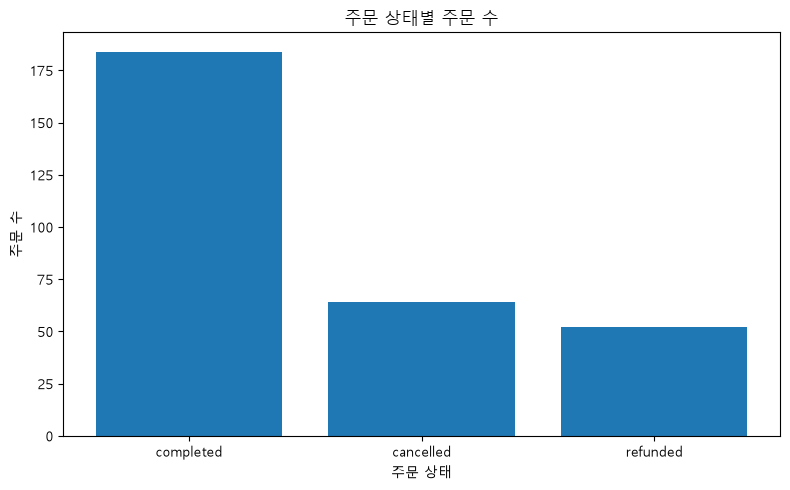

In [20]:
plt.figure(figsize=(8, 5))
plt.bar(order_status['order_status'], order_status['order_count'])
plt.title('주문 상태별 주문 수')
plt.xlabel('주문 상태')
plt.ylabel('주문 수')
plt.tight_layout()
plt.savefig(FIGURE_DIR / 'ch07_order_status_bar.png', dpi=150, bbox_inches='tight')
plt.show()


## 13. 저장된 그래프 확인하기

생성된 그래프 파일을 확인합니다. 보고서나 발표 자료에 사용할 수 있도록 `reports/figures` 폴더에 저장했습니다.


In [21]:
list(FIGURE_DIR.glob('ch07_*.png'))


[WindowsPath('c:/dev/llm-data-analysis-course/reports/figures/ch07_category_sales_bar.png'),
 WindowsPath('c:/dev/llm-data-analysis-course/reports/figures/ch07_completed_category_sales_bar.png'),
 WindowsPath('c:/dev/llm-data-analysis-course/reports/figures/ch07_completed_monthly_sales_line.png'),
 WindowsPath('c:/dev/llm-data-analysis-course/reports/figures/ch07_monthly_sales_line.png'),
 WindowsPath('c:/dev/llm-data-analysis-course/reports/figures/ch07_order_status_bar.png'),
 WindowsPath('c:/dev/llm-data-analysis-course/reports/figures/ch07_price_quantity_scatter.png'),
 WindowsPath('c:/dev/llm-data-analysis-course/reports/figures/ch07_product_price_hist.png'),
 WindowsPath('c:/dev/llm-data-analysis-course/reports/figures/ch07_product_price_hist_10k.png'),
 WindowsPath('c:/dev/llm-data-analysis-course/reports/figures/ch07_top_customers_barh.png')]

## 14. 시각화 요약표 만들기

각 그래프의 목적과 해석 포인트를 표로 정리하면 이후 보고서 작성이 쉬워집니다.


In [22]:
visualization_summary = pd.DataFrame({
    'chart': [
        '카테고리별 매출 막대그래프',
        '월별 매출 선 그래프',
        '상품 가격 분포 히스토그램',
        '상품 가격과 판매 수량 산점도',
        '구매 금액 상위 고객 가로 막대그래프',
        '주문 상태별 주문 수 막대그래프',
    ],
    'question': [
        '카테고리별 매출은 어떻게 다른가?',
        '월별 매출은 어떻게 변하는가?',
        '상품 가격은 어떤 구간에 몰려 있는가?',
        '상품 가격과 판매 수량은 관계가 있는가?',
        '구매 금액이 높은 고객은 누구인가?',
        '주문 상태별 주문 수는 어떻게 다른가?',
    ],
    'interpretation_point': [
        '매출 기여도가 높은 카테고리 확인',
        '시간에 따른 증가와 감소 흐름 확인',
        '상품 가격대의 분포와 이상값 후보 확인',
        '가격과 판매 수량의 관계 탐색',
        '우수 고객 후보 확인',
        '완료, 취소 등 주문 상태 분포 확인',
    ],
    'file_name': [
        'ch07_category_sales_bar.png',
        'ch07_monthly_sales_line.png',
        'ch07_product_price_hist.png',
        'ch07_price_quantity_scatter.png',
        'ch07_top_customers_barh.png',
        'ch07_order_status_bar.png',
    ],
})

visualization_summary


,chart,question,interpretation_point,file_name
0,카테고리별 매출 막대그래프,카테고리별 매출은 어떻게 다른가?,매출 기여도가 높은 카테고리 확인,ch07_category_sales_bar.png
1,월별 매출 선 그래프,월별 매출은 어떻게 변하는가?,시간에 따른 증가와 감소 흐름 확인,ch07_monthly_sales_line.png
2,상품 가격 분포 히스토그램,상품 가격은 어떤 구간에 몰려 있는가?,상품 가격대의 분포와 이상값 후보 확인,ch07_product_price_hist.png
3,상품 가격과 판매 수량 산점도,상품 가격과 판매 수량은 관계가 있는가?,가격과 판매 수량의 관계 탐색,ch07_price_quantity_scatter.png
4,구매 금액 상위 고객 가로 막대그래프,구매 금액이 높은 고객은 누구인가?,우수 고객 후보 확인,ch07_top_customers_barh.png
5,주문 상태별 주문 수 막대그래프,주문 상태별 주문 수는 어떻게 다른가?,"완료, 취소 등 주문 상태 분포 확인",ch07_order_status_bar.png


## 15. 시각화 요약 보고서 저장하기

시각화 목적, 생성한 그래프 목록, 해석 포인트, 주의사항을 Markdown 보고서로 저장합니다.


In [23]:
summary_text = f'''# Chapter 7 데이터 시각화 요약 보고서

## 1. 시각화 목적

전처리 및 EDA 결과를 바탕으로 온라인 쇼핑몰 데이터의 주요 패턴을 그래프로 확인했습니다.

## 2. 생성한 그래프 목록

```text
{visualization_summary.to_string(index=False)}
```

## 3. 주요 해석 포인트

- 카테고리별 매출 그래프를 통해 매출 기여도가 높은 상품군을 확인할 수 있습니다.
- 월별 매출 선 그래프를 통해 시간에 따른 매출 흐름을 확인할 수 있습니다.
- 상품 가격 히스토그램을 통해 상품 가격대 분포를 확인할 수 있습니다.
- 가격과 판매 수량 산점도는 두 변수 사이의 관계를 탐색하는 데 사용합니다.
- 고객별 구매 금액 상위 그래프는 우수 고객 후보를 파악하는 데 유용합니다.
- 주문 상태별 주문 수 그래프는 완료, 취소 등 주문 상태의 분포를 확인하는 데 사용합니다.

## 4. 해석 시 주의사항

- 그래프는 데이터를 쉽게 보여주지만 원인을 자동으로 설명하지는 않습니다.
- 매출이 높은 이유는 판매 수량, 단가, 주문 수 등을 함께 확인해야 합니다.
- 고객명 등 개인정보가 포함될 수 있는 그래프는 익명화가 필요할 수 있습니다.
- 시각화 결과는 보고서에 넣기 전에 축, 제목, 단위가 명확한지 확인해야 합니다.

## 5. 다음 단계

다음 장에서는 지금까지 배운 데이터 불러오기, 전처리, EDA, 시각화를 종합하여 중간 실습 프로젝트를 수행합니다.
'''

summary_path = REPORT_DIR / 'ch07_visualization_summary.md'
summary_path.write_text(summary_text, encoding='utf-8')

print('시각화 요약 보고서 저장 완료:', summary_path)


시각화 요약 보고서 저장 완료: c:\dev\llm-data-analysis-course\reports\ch07_visualization_summary.md


## 16. 소스 모듈로 같은 시각화 실행하기

위에서 노트북으로 한 단계씩 실행한 시각화는 `src/visualization.py`에 함수로 정리되어 있습니다. 반복 실행하거나 프로젝트 코드로 관리하려면 소스 모듈을 사용하는 것이 좋습니다.


In [24]:
from src.visualization import (
    create_all_figures,
    create_visualization_summary,
    prepare_visualization_data,
    setup_korean_font,
)

setup_korean_font()
module_viz_data = prepare_visualization_data(PROCESSED_DIR)
module_viz_summary = create_visualization_summary()
module_viz_summary


,chart,question,interpretation_point,file_name
0,카테고리별 매출 막대그래프,카테고리별 매출은 어떻게 다른가?,매출 기여도가 높은 카테고리 확인,ch07_category_sales_bar.png
1,월별 매출 선 그래프,월별 매출은 어떻게 변하는가?,시간에 따른 증가와 감소 흐름 확인,ch07_monthly_sales_line.png
2,상품 가격 분포 히스토그램,상품 가격은 어떤 구간에 몰려 있는가?,상품 가격대의 분포와 이상값 후보 확인,ch07_product_price_hist.png
3,상품 가격과 판매 수량 산점도,상품 가격과 판매 수량은 관계가 있는가?,가격과 판매 수량의 관계 탐색,ch07_price_quantity_scatter.png
4,구매 금액 상위 고객 가로 막대그래프,구매 금액이 높은 고객은 누구인가?,우수 고객 후보 확인,ch07_top_customers_barh.png
5,주문 상태별 주문 수 막대그래프,주문 상태별 주문 수는 어떻게 다른가?,"완료, 취소 등 주문 상태 분포 확인",ch07_order_status_bar.png


## 17. 스크립트로 한 번에 실행하기

노트북에서 한 단계씩 이해한 시각화 과정을 스크립트로도 실행할 수 있습니다. 터미널에서 프로젝트 루트 기준으로 아래 명령을 실행합니다.

```bash
python scripts/run_visualization.py
```

이 스크립트는 7장 그래프 파일 6개와 `reports/ch07_visualization_summary.md`를 자동으로 저장합니다.


## 18. LLM에게 그래프 선택과 해석 요청하기

LLM은 그래프 선택, matplotlib 코드 작성, 해석 문장 작성에 도움을 줄 수 있습니다. 하지만 그래프 해석은 반드시 실제 데이터와 비교해야 합니다.

```text
온라인 쇼핑몰 데이터에서 다음 분석 질문을 시각화하려고 합니다.

분석 질문:
1. 카테고리별 매출은 어떻게 다른가?
2. 월별 매출은 어떻게 변하는가?
3. 상품 가격은 어떤 구간에 몰려 있는가?
4. 상품 가격과 판매 수량은 관계가 있는가?
5. 구매 금액 상위 고객은 누구인가?

각 질문에 적합한 그래프 종류를 추천해 주세요.
각 그래프를 선택한 이유와 주의할 점도 함께 설명해 주세요.
```


### llm 답변 요약

|분석 질문|추천 그래프|핵심 목적|
|---|---|---|
|카테고리별 매출|막대그래프|범주 간 크기 비교|
|월별 매출|선그래프|시간에 따른 추세|
|상품 가격 분포|히스토그램|수치형 변수의 분포|
|가격과 판매 수량|산점도|두 수치형 변수의 관계|
|구매 금액 상위 고객|가로 막대그래프|상위 항목 순위 비교|

- 추천하는 진행 순서: 카테고리별 매출 → 월별 매출 → 상품 가격 분포 → 가격과 판매 수량 관계 → 상위 고객 순으로 진행해 보세요. 먼저 전체적인 매출 구조를 파악한 뒤 상품 및 고객 수준으로 분석 범위를 좁히면 결과를 설명하기가 더 쉽습니다.


## 19. 그래프 해석 요청 예시

그래프 해석을 요청할 때는 데이터에 없는 원인을 단정하지 말라는 조건을 넣는 것이 좋습니다.

```text
다음은 카테고리별 매출 그래프를 만들기 위한 요약 데이터입니다.

category,total_sales,sales_ratio
전자기기,12500000,42.5
생활용품,7800000,26.5
패션,6200000,21.1
식품,2900000,9.9

이 그래프를 보고서에 넣을 수 있도록 해석 문장을 작성해 주세요.

조건:
- 데이터에 없는 원인을 단정하지 말 것
- 관찰 결과와 원인 가설을 구분할 것
- 추가로 확인해야 할 분석 질문을 제안할 것
- 초보자도 이해할 수 있게 작성할 것
```


### llm 답변 요약
1. 카테고리별 매출 분포 분석
### 카테고리별 매출 분포 분석

카테고리별 매출을 비교한 결과, **전자기기의 매출이 1,250만 원으로 전체의 42.5%를 차지해 가장 높은 비중**을 보였다. 다음으로 생활용품이 780만 원(26.5%), 패션이 620만 원(21.1%), 식품이 290만 원(9.9%) 순으로 나타났다.

전자기기와 생활용품의 매출 비중을 합하면 69.0%로, 전체 매출의 약 3분의 2 이상을 차지한다. 반면 식품의 매출 비중은 9.9%로 네 가지 카테고리 중 가장 낮았다. 따라서 제공된 데이터에서는 카테고리별 매출이 균등하게 분포하기보다는 전자기기와 생활용품에 상대적으로 집중되어 있음을 확인할 수 있다.

다만 이러한 차이가 발생한 원인은 현재 데이터만으로 판단하기 어렵다. 카테고리별 상품 수, 상품 가격, 판매 수량 등이 매출 차이와 관련이 있는지 추가로 분석할 필요가 있다.

2. 관찰 결과와 원인 가설 구분하기
|구분|해석|
|---|---|
|관찰 결과|전자기기의 매출 비중이 42.5%로 가장 높다.|
|관찰 결과|식품의 매출 비중은 9.9%로 가장 낮다.|
|관찰 결과|전자기기와 생활용품이 전체 매출의 69.0%를 차지한다.|
|원인 가설|전자기기의 평균 상품 가격이 다른 카테고리보다 높을 수 있다.|
|원인 가설|전자기기의 판매 수량이 상대적으로 많을 수 있다.|
|원인 가설|카테고리별 상품 수의 차이가 매출 분포에 영향을 주었을 수 있다.|

주의: 위의 원인 가설은 추가로 검증해야 할 가능성일 뿐, 현재 그래프만으로 확인된 사실은 아니다.

3. 추가로 확인하면 좋은 분석 질문
    - 카테고리별 상품 수는 얼마나 다른가?
    - 카테고리별 총판매 수량은 어떻게 다른가?
    - 카테고리별 평균 상품 가격은 얼마인가?
    - 월별로 보았을 때도 전자기기의 매출 비중이 높은가?

4. 분석할 때 추가로 주의할 점
    - 매출 기준 확인: 취소·환불 주문을 제외한 매출인지, 전체 주문의 상품 금액을 합산한 것인지 보고서에 명시해야 한다.
    - 비율의 기준 확인: sales_ratio가 어떤 전체 매출을 기준으로 계산되었는지 확인한다. 제공된 네 카테고리의 비율 합계는 100%이므로, 네 카테고리만을 대상으로 계산한 비율로 보인다.
    - 매출과 이익 구분: 매출이 높다고 반드시 이익도 높은 것은 아니다. 현재 데이터에 원가 정보가 없다면 이익에 대해서는 판단할 수 없다.

## 20. 시각화 점검 체크리스트

그래프를 보고서에 넣기 전에 아래 항목을 점검합니다.

| 점검 항목 | 확인 |
|---|---|
| 분석 질문에 맞는 그래프를 선택했는가? | [x] |
| 그래프 제목이 명확한가? | [x] |
| x축과 y축 이름을 표시했는가? | [x] |
| 필요한 경우 단위를 표시했는가? | [x] |
| 범주형 데이터가 읽기 좋은 순서로 정렬되었는가? | [x] |
| 시간 데이터가 올바른 순서로 정렬되었는가? | [x] |
| 한글 폰트가 깨지지 않는가? | [x] |
| 그래프 해석에서 관찰과 원인을 구분했는가? | [x] |
| 개인정보가 필요한 경우 익명화했는가? | [x] |
| 그래프 파일을 저장했는가? | [x] |


## 21. 실습 과제

아래 과제를 직접 해결해 보세요.

1. 카테고리별 판매 수량 막대그래프를 추가로 그려 보세요.
2. 결제수단별 주문 수 막대그래프를 그려 보세요.
3. 고객 나이 분포 히스토그램을 그려 보세요.
4. 월별 주문 수 선 그래프를 그려 보세요.
5. 고객별 주문 횟수와 총 구매 금액의 관계를 산점도로 그려 보세요.
6. 위 그래프 중 2개를 `reports/figures` 폴더에 저장하세요.


카테고리 누락: 0
카테고리 수량 합계 = completed 수량 합계: True


,category,total_quantity,quantity_ratio
0,스포츠,295,20.46
1,생활용품,272,18.86
2,전자기기,259,17.96
3,뷰티,223,15.46
4,도서,149,10.33
5,식품,133,9.22
6,패션,111,7.70


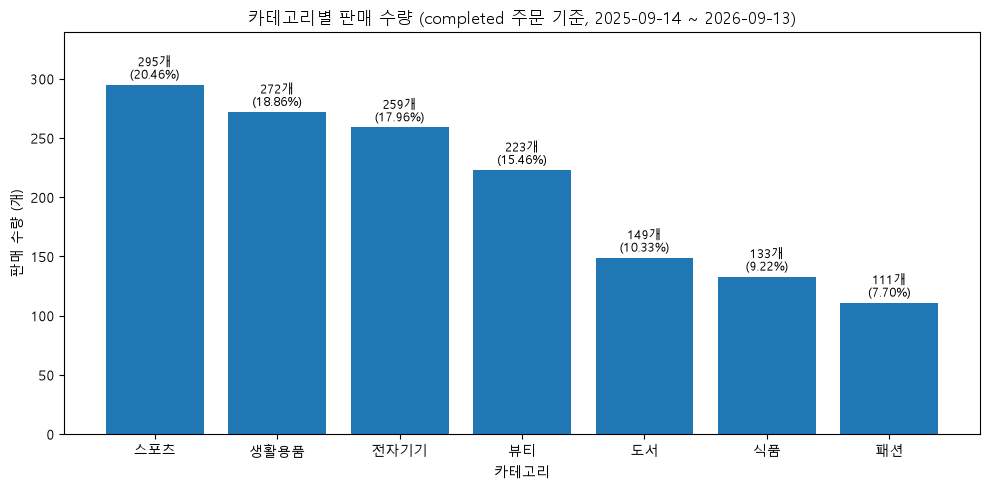

막대 높이 = 집계표 total_quantity: True


In [25]:
# 과제 1. 카테고리별 판매 수량 막대그래프를 추가로 그려 보세요. (completed 주문 기준)
period = f"{orders['order_date'].min():%Y-%m-%d} ~ {orders['order_date'].max():%Y-%m-%d}"

completed_items_qty = (
    order_sales[order_sales['order_status'] == 'completed']
    .merge(products[['product_id', 'category']], on='product_id', how='left')
)

category_quantity = (
    completed_items_qty
    .groupby('category', as_index=False)
    .agg(total_quantity=('quantity', 'sum'))
    .sort_values('total_quantity', ascending=False)
    .reset_index(drop=True)
)
category_quantity['quantity_ratio'] = (
    category_quantity['total_quantity'] / category_quantity['total_quantity'].sum() * 100
).round(2)

print('카테고리 누락:', completed_items_qty['category'].isna().sum())
print('카테고리 수량 합계 = completed 수량 합계:',
      category_quantity['total_quantity'].sum() == completed_items_qty['quantity'].sum())
display(category_quantity)

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(category_quantity['category'], category_quantity['total_quantity'])
label_offset = category_quantity['total_quantity'].max() * 0.01
for bar, qty, ratio in zip(bars, category_quantity['total_quantity'], category_quantity['quantity_ratio']):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + label_offset,
            f'{qty:,}개\n({ratio:.2f}%)', ha='center', va='bottom', fontsize=9)

ax.set_title(f'카테고리별 판매 수량 (completed 주문 기준, {period})')
ax.set_xlabel('카테고리')
ax.set_ylabel('판매 수량 (개)')
ax.set_ylim(0, category_quantity['total_quantity'].max() * 1.15)
plt.tight_layout()
plt.savefig(FIGURE_DIR / 'ch07_task1_category_quantity_bar.png', dpi=150, bbox_inches='tight')
plt.show()

print('막대 높이 = 집계표 total_quantity:',
      [bar.get_height() for bar in bars] == category_quantity['total_quantity'].tolist())

전체 주문 합계: 300 / orders 행 수: 300
completed 주문 합계: 184 / completed 주문 수: 184


,payment_method,all_orders,completed_orders,completed_ratio
0,kakao_pay,79,49,62.0
1,naver_pay,77,51,66.2
2,bank_transfer,74,45,60.8
3,card,70,39,55.7


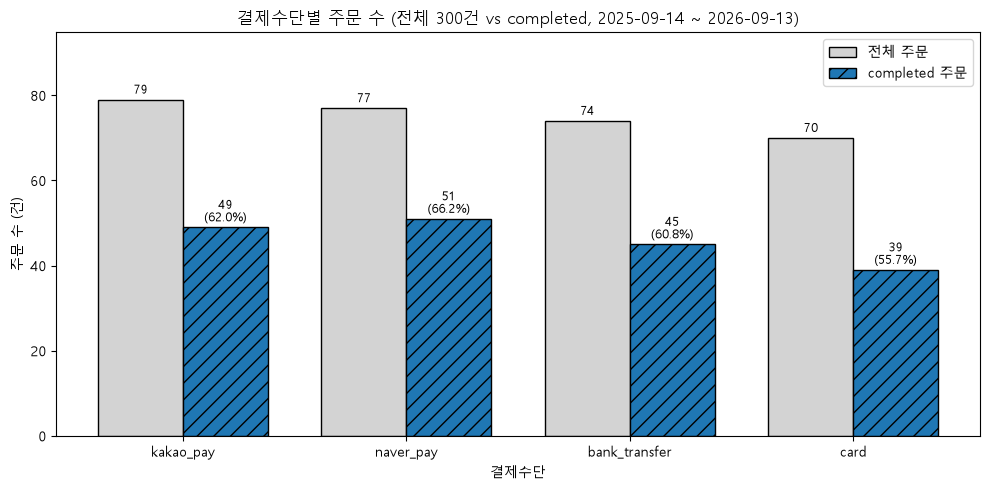

전체 주문 막대 = 집계표: True
completed 막대 = 집계표: True


In [28]:
# 과제 2. 결제수단별 주문 수 막대그래프를 그려 보세요. (전체 주문과 completed 주문 비교)
import numpy as np

period = f"{orders['order_date'].min():%Y-%m-%d} ~ {orders['order_date'].max():%Y-%m-%d}"

payment_orders = (
    orders
    .groupby('payment_method', as_index=False)
    .agg(
        all_orders=('order_id', 'nunique'),
        completed_orders=('order_status', lambda s: (s == 'completed').sum()),
    )
    .sort_values('all_orders', ascending=False)
    .reset_index(drop=True)
)
payment_orders['completed_ratio'] = (
    payment_orders['completed_orders'] / payment_orders['all_orders'] * 100
).round(1)

print('전체 주문 합계:', payment_orders['all_orders'].sum(), '/ orders 행 수:', len(orders))
print('completed 주문 합계:', payment_orders['completed_orders'].sum(),
      '/ completed 주문 수:', (orders['order_status'] == 'completed').sum())
display(payment_orders)

x = np.arange(len(payment_orders))
width = 0.38
fig, ax = plt.subplots(figsize=(10, 5))
all_bars = ax.bar(x - width / 2, payment_orders['all_orders'], width,
                  label='전체 주문', color='lightgray', edgecolor='black')
completed_bars = ax.bar(x + width / 2, payment_orders['completed_orders'], width,
                        label='completed 주문', hatch='//', edgecolor='black')

for bar, count in zip(all_bars, payment_orders['all_orders']):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.8, f'{count}',
            ha='center', va='bottom', fontsize=9)
for bar, count, ratio in zip(completed_bars, payment_orders['completed_orders'], payment_orders['completed_ratio']):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.8, f'{count}\n({ratio:.1f}%)',
            ha='center', va='bottom', fontsize=9)

ax.set_xticks(x)
ax.set_xticklabels(payment_orders['payment_method'])
ax.set_title(f'결제수단별 주문 수 (전체 {len(orders)}건 vs completed, {period})')
ax.set_xlabel('결제수단')
ax.set_ylabel('주문 수 (건)')
ax.set_ylim(0, payment_orders['all_orders'].max() * 1.2)
ax.legend()
plt.tight_layout()
plt.show()

print('전체 주문 막대 = 집계표:', [bar.get_height() for bar in all_bars] == payment_orders['all_orders'].tolist())
print('completed 막대 = 집계표:', [bar.get_height() for bar in completed_bars] == payment_orders['completed_orders'].tolist())

고객 수: 150 / 나이 결측: 0


,count,mean,std,min,25%,50%,75%,max
age,150.0,42.09,15.61,19.0,29.0,40.0,57.0,69.0


,age_from,age_to,customer_count
0,15,20,5
1,20,25,21
2,25,30,13
3,30,35,22
4,35,40,11
5,40,45,15
6,45,50,5
7,50,55,11
8,55,60,16
9,60,65,17


,age_group,customer_count
0,20세 미만,5
1,20대,34
2,30대,33
3,40대,20
4,50대,27
5,60대 이상,31


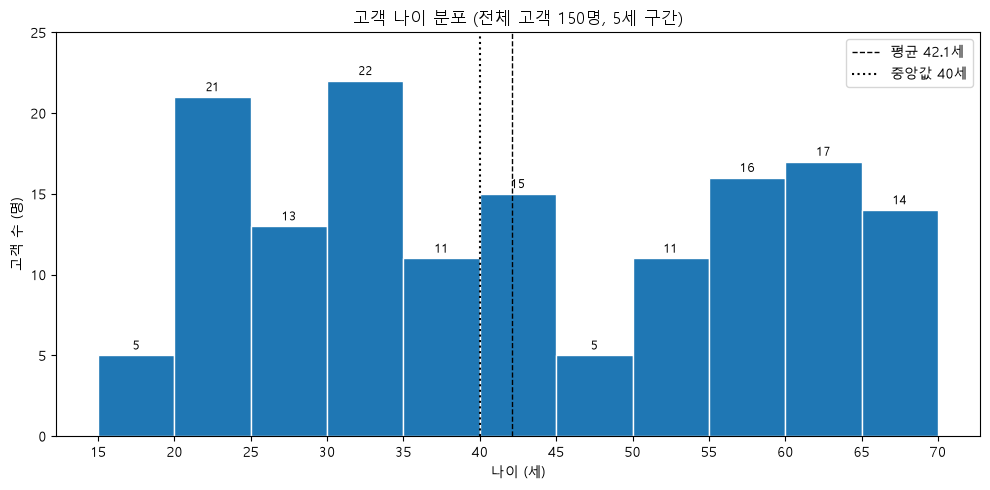

히스토그램 막대 높이 = 구간 집계표: True
구간 합계 = 고객 수: True


In [29]:
# 과제 3. 고객 나이 분포 히스토그램을 그려 보세요. (전체 고객 기준, 주문 상태와 무관)
import numpy as np

age = customers['age']

print('고객 수:', len(customers), '/ 나이 결측:', age.isna().sum())
display(age.describe().round(2).to_frame('age').T)

age_bin_width = 5
age_edges = np.arange(
    np.floor(age.min() / age_bin_width) * age_bin_width,
    np.ceil(age.max() / age_bin_width) * age_bin_width + age_bin_width,
    age_bin_width,
)
age_counts, _ = np.histogram(age, bins=age_edges)
age_bin_table = pd.DataFrame({
    'age_from': age_edges[:-1].astype(int),
    'age_to': age_edges[1:].astype(int),
    'customer_count': age_counts,
})
display(age_bin_table)

age_group_table = (
    pd.cut(
        age,
        bins=[0, 20, 30, 40, 50, 60, max(70, age.max() + 1)],
        right=False,
        labels=['20세 미만', '20대', '30대', '40대', '50대', '60대 이상'],
    )
    .value_counts(sort=False)
    .rename_axis('age_group')
    .reset_index(name='customer_count')
)
display(age_group_table)

fig, ax = plt.subplots(figsize=(10, 5))
hist_counts, _, patches = ax.hist(age, bins=age_edges, edgecolor='white')
for patch, count in zip(patches, hist_counts):
    if count > 0:
        ax.text(patch.get_x() + patch.get_width() / 2, count + 0.2, f'{int(count)}',
                ha='center', va='bottom', fontsize=9)

ax.axvline(age.mean(), color='black', linestyle='--', linewidth=1, label=f'평균 {age.mean():.1f}세')
ax.axvline(age.median(), color='black', linestyle=':', linewidth=1.5, label=f'중앙값 {age.median():.0f}세')
ax.set_title(f'고객 나이 분포 (전체 고객 {len(customers)}명, {age_bin_width}세 구간)')
ax.set_xlabel('나이 (세)')
ax.set_ylabel('고객 수 (명)')
ax.set_xticks(age_edges)
ax.set_ylim(0, hist_counts.max() + 3)
ax.legend()
plt.tight_layout()
plt.show()

print('히스토그램 막대 높이 = 구간 집계표:', hist_counts.astype(int).tolist() == age_bin_table['customer_count'].tolist())
print('구간 합계 = 고객 수:', int(hist_counts.sum()) == len(customers))

월 순서 정렬: True
누락된 월(주문 0건): []
전체 주문 합계: 300 / completed 합계: 184


,order_month,all_orders,completed_orders,completed_ratio,observed_days,is_partial
0,2025-09,10,5,50.0,17,True
1,2025-10,27,19,70.4,31,False
2,2025-11,21,13,61.9,30,False
3,2025-12,35,24,68.6,31,False
4,2026-01,29,16,55.2,31,False
5,2026-02,16,7,43.8,28,False
6,2026-03,34,24,70.6,31,False
7,2026-04,28,17,60.7,30,False
8,2026-05,27,18,66.7,31,False
9,2026-06,26,18,69.2,30,False


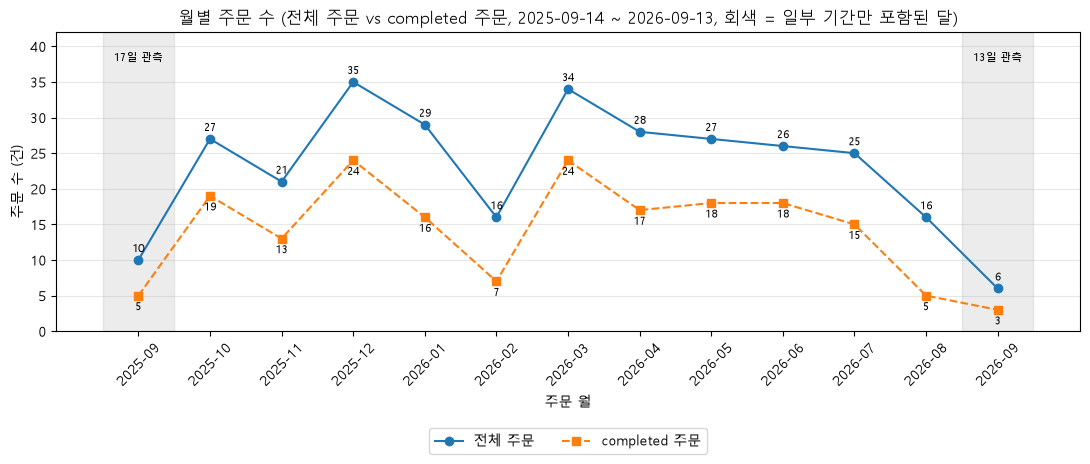

전체 주문 선 = 집계표: True
completed 선 = 집계표: True


In [30]:
# 과제 4. 월별 주문 수 선 그래프를 그려 보세요. (전체 주문과 completed 주문 비교)
period = f"{orders['order_date'].min():%Y-%m-%d} ~ {orders['order_date'].max():%Y-%m-%d}"

first_date = orders['order_date'].min().normalize()
last_date = orders['order_date'].max().normalize()
all_months = pd.period_range(first_date, last_date, freq='M').astype(str)

monthly_orders = (
    orders
    .groupby('order_month')
    .agg(
        all_orders=('order_id', 'nunique'),
        completed_orders=('order_status', lambda s: (s == 'completed').sum()),
    )
    .reindex(all_months, fill_value=0)
    .rename_axis('order_month')
    .reset_index()
)
monthly_orders['completed_ratio'] = (
    monthly_orders['completed_orders'] / monthly_orders['all_orders'].where(monthly_orders['all_orders'] > 0) * 100
).round(1)

month_start = pd.to_datetime(monthly_orders['order_month'])
month_end = month_start + pd.offsets.MonthEnd(0)
monthly_orders['observed_days'] = (
    month_end.clip(upper=last_date) - month_start.clip(lower=first_date)
).dt.days + 1
monthly_orders['is_partial'] = monthly_orders['observed_days'] < month_end.dt.day

print('월 순서 정렬:', monthly_orders['order_month'].is_monotonic_increasing)
print('누락된 월(주문 0건):', monthly_orders.loc[monthly_orders['all_orders'] == 0, 'order_month'].tolist())
print('전체 주문 합계:', monthly_orders['all_orders'].sum(), '/ completed 합계:', monthly_orders['completed_orders'].sum())
display(monthly_orders)

fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(monthly_orders['order_month'], monthly_orders['all_orders'],
        marker='o', linestyle='-', label='전체 주문')
ax.plot(monthly_orders['order_month'], monthly_orders['completed_orders'],
        marker='s', linestyle='--', label='completed 주문')

for position, row in monthly_orders.reset_index(drop=True).iterrows():
    ax.text(position, row['all_orders'] + 0.8, f"{row['all_orders']}", ha='center', va='bottom', fontsize=8)
    ax.text(position, row['completed_orders'] - 0.8, f"{row['completed_orders']}", ha='center', va='top', fontsize=8)
    if row['is_partial']:
        ax.axvspan(position - 0.5, position + 0.5, color='gray', alpha=0.15)
        ax.text(position, monthly_orders['all_orders'].max() * 1.12, f"{row['observed_days']}일 관측",
                ha='center', va='top', fontsize=8)

ax.set_title(f'월별 주문 수 (전체 주문 vs completed 주문, {period}, 회색 = 일부 기간만 포함된 달)')
ax.set_xlabel('주문 월')
ax.set_ylabel('주문 수 (건)')
ax.set_ylim(0, monthly_orders['all_orders'].max() * 1.2)
ax.grid(axis='y', alpha=0.3)
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.3), ncol=2)
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(FIGURE_DIR / 'ch07_task4_monthly_orders_line.png', dpi=150, bbox_inches='tight')
plt.show()

print('전체 주문 선 = 집계표:', list(ax.lines[0].get_ydata()) == monthly_orders['all_orders'].tolist())
print('completed 선 = 집계표:', list(ax.lines[1].get_ydata()) == monthly_orders['completed_orders'].tolist())

completed 구매 고객 수: 100 / 전체 고객: 150
고객별 합계 = completed 원본 합계: True
상관계수(Pearson): 0.751
순위 상관계수(Spearman): 0.689


,order_count,customer_count,mean_total_sales,median_total_sales,min_total_sales,max_total_sales
0,1,44,852523.0,870500.0,118000,1931000
1,2,37,1665486.0,1620000.0,112000,3191000
2,3,12,2104583.0,1958500.0,1032000,3153000
3,4,5,3382200.0,3523000.0,2419000,3996000
4,5,2,3845000.0,3845000.0,3590000,4100000


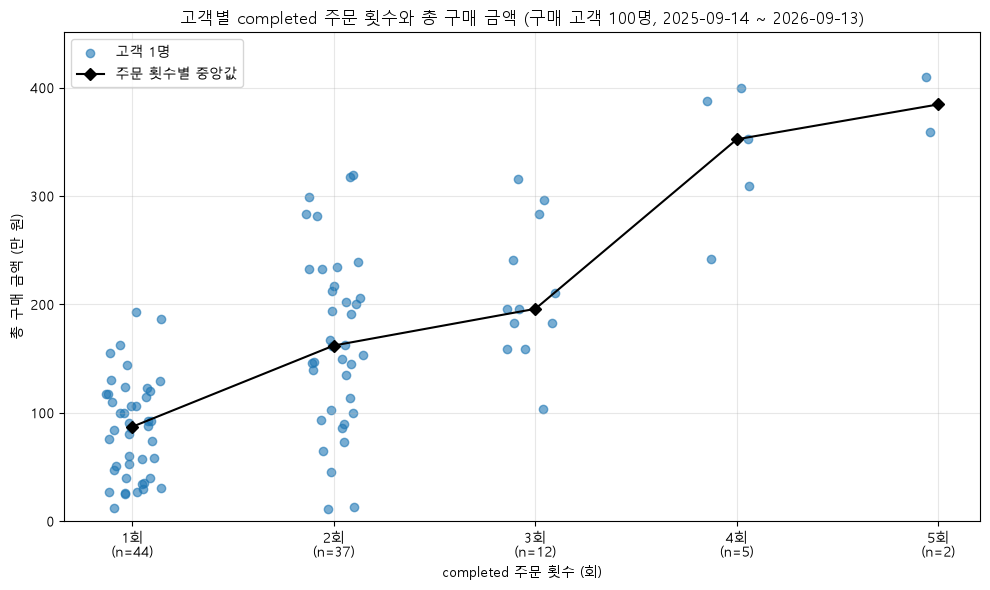

점의 y값 = 집계표 total_sales: True


In [32]:
# 과제 5. 고객별 주문 횟수와 총 구매 금액의 관계를 산점도로 그려 보세요. (completed 주문 기준)
import numpy as np
from matplotlib.ticker import FuncFormatter

period = f"{orders['order_date'].min():%Y-%m-%d} ~ {orders['order_date'].max():%Y-%m-%d}"

completed_customer_sales = (
    order_sales[order_sales['order_status'] == 'completed']
    .groupby('customer_id', as_index=False)
    .agg(
        order_count=('order_id', 'nunique'),
        total_sales=('line_total', 'sum'),
    )
)

order_count_summary = (
    completed_customer_sales
    .groupby('order_count', as_index=False)
    .agg(
        customer_count=('customer_id', 'count'),
        mean_total_sales=('total_sales', 'mean'),
        median_total_sales=('total_sales', 'median'),
        min_total_sales=('total_sales', 'min'),
        max_total_sales=('total_sales', 'max'),
    )
    .round(0)
)

print('completed 구매 고객 수:', len(completed_customer_sales), '/ 전체 고객:', len(customers))
print('고객별 합계 = completed 원본 합계:',
      completed_customer_sales['total_sales'].sum()
      == order_sales.loc[order_sales['order_status'] == 'completed', 'line_total'].sum())
print('상관계수(Pearson):', round(completed_customer_sales['order_count'].corr(completed_customer_sales['total_sales']), 3))
print('순위 상관계수(Spearman):',
      round(completed_customer_sales['order_count'].corr(completed_customer_sales['total_sales'], method='spearman'), 3))
display(order_count_summary)

jitter = np.random.default_rng(42).uniform(-0.15, 0.15, len(completed_customer_sales))

fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(completed_customer_sales['order_count'] + jitter, completed_customer_sales['total_sales'],
           alpha=0.6, label='고객 1명')
ax.plot(order_count_summary['order_count'], order_count_summary['median_total_sales'],
        color='black', marker='D', linestyle='-', label='주문 횟수별 중앙값')

ax.set_xticks(order_count_summary['order_count'])
ax.set_xticklabels([f'{k}회\n(n={n})' for k, n in zip(order_count_summary['order_count'], order_count_summary['customer_count'])])
ax.set_title(f'고객별 completed 주문 횟수와 총 구매 금액 (구매 고객 {len(completed_customer_sales)}명, {period})')
ax.set_xlabel('completed 주문 횟수 (회)')
ax.set_ylabel('총 구매 금액 (만 원)')
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{v / 10_000:,.0f}'))
ax.set_ylim(0, completed_customer_sales['total_sales'].max() * 1.1)
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

print('점의 y값 = 집계표 total_sales:',
      ax.collections[0].get_offsets()[:, 1].tolist() == completed_customer_sales['total_sales'].tolist())

In [33]:
# 과제 6. 위 그래프 중 2개를 reports/figures 폴더에 저장하세요.
saved_figures = [
    FIGURE_DIR / 'ch07_task1_category_quantity_bar.png',
    FIGURE_DIR / 'ch07_task4_monthly_orders_line.png',
]
for path in saved_figures:
    size_kb = path.stat().st_size / 1024 if path.exists() else 0
    print(f'{path.name}: 존재={path.exists()}, 크기={size_kb:,.1f} KB')

ch07_task1_category_quantity_bar.png: 존재=True, 크기=47.2 KB
ch07_task4_monthly_orders_line.png: 존재=True, 크기=109.7 KB


## 22. 정리

이번 장에서는 다음 내용을 실습했습니다.

- 분석 질문에 맞는 그래프 선택
- matplotlib 기본 구조와 한글 폰트 설정
- 시각화를 위한 집계 데이터 준비
- 카테고리별 매출 막대그래프
- 월별 매출 선 그래프
- 상품 가격 분포 히스토그램
- 상품 가격과 판매 수량 산점도
- 구매 금액 상위 고객 가로 막대그래프와 익명화
- 주문 상태별 주문 수 막대그래프
- 그래프 파일 저장과 시각화 요약 보고서 작성
- `src/visualization.py`와 `scripts/run_visualization.py`로 반복 실행 가능한 구조 만들기

다음 장에서는 지금까지 배운 데이터 불러오기, 전처리, EDA, 시각화를 종합하여 중간 실습 프로젝트를 수행합니다.


## assignment markdown

# Chapter 07 답안 양식. 그래프로 데이터의 이야기를 보여주기

> 이 내용을 `chapter07.ipynb`의 Markdown 셀로 작성합니다.

## 제출 정보
- 이름: 배성윤
- GitHub ID: aeuyui
- 작성일: 2026-10-27
- 최종 Notebook URL: https://github.com/aeuyui/llm-data-analysis-study/blob/main/chapter07/chapter07.ipynb

## 1. 시각화 질문과 그래프 선택
| 질문 | 선택한 그래프 | 선택 이유 |
| --- | --- | --- |
| completed 주문 기준 카테고리별 매출은 어떻게 다른가? | 세로 막대그래프 (매출 내림차순 정렬) | 순서가 없는 7개 범주의 크기를 비교하는 질문이다. 막대 길이로 차이를 보여 주고, 매출 순으로 정렬해 상위/하위 범주를 바로 읽을 수 있다.|
| completed 주문 기준 월별 매출은 어떻게 변하는가? | 선그래프 (월 순서 정렬, 점 표시) | 13개월의 시간 순서와 증감 흐름을 보는 질문이다. 선으로 이어 연속 변화와 일시적 변화를 구분해 볼 수 있다. x축은 월 순서대로 정렬한다. |
| 등록된 상품 100개의 가격은 어떤 구간에 몰려 있는가? | 히스토그램 (20개 구간) | 숫자형 변수의 분포를 보는 질문이다. 구간별 상품 수로 값이 몰린 구간, 긴 꼬리, 극단값 후보를 확인할 수 있다. 상품 목록의 가격이므로 주문 상태 필터는 적용하지 않는다. |

## 2. 대표 그래프 1
![대표 그래프 1](images/graph01.png)

### 원본 집계값
completed 주문 184건의 주문 상세 474행 기준이며, 합계는 148,990,000원이다. 카테고리 합계와 원본 합계가 같고, 그래프의 막대 높이와 집계표 값도 같다.

| 순위 | 카테고리 | 판매 수량 | 매출(원) | 비중(%) |
|---|---|---:|---:|---:|
| 1 | 스포츠 | 295 | 31,743,000 | 21.31 |
| 2 | 전자기기 | 259 | 26,400,000 | 17.72 |
| 3 | 생활용품 | 272 | 23,915,000 | 16.05 |
| 4 | 뷰티 | 223 | 23,383,000 | 15.69 |
| 5 | 식품 | 133 | 16,573,000 | 11.12 |
| 6 | 도서 | 149 | 16,389,000 | 11.00 |
| 7 | 패션 | 111 | 10,587,000 | 7.11 |
| | 합계 | 1,442 | 148,990,000 | 100.00 |

### 결과 관찰
- 1위 스포츠(3,174만 원)와 7위 패션(1,059만 원)의 차이는 2,116만 원으로, 스포츠가 패션의 약 3배이다.
- 이웃한 순위 중 생활용품과 뷰티는 53.2만 원(0.36%p), 식품과 도서는 18.4만 원(0.12%p) 차이로 그래프에서 거의 같은 높이이다.
- 상위 4개 카테고리가 전체 매출의 70.77%를 차지한다.

### 나의 해석과 판단
- 스포츠의 1위와 패션의 최하위는 차이가 커서 순위로 말할 수 있다. 반면 생활용품과 뷰티, 식품과 도서는 차이가 작아 주문 몇 건으로 순위가 바뀔 수 있으므로 비슷한 수준으로 해석할 수 있다.
- 같은 데이터라도 전체 상태 기준 그래프에서는 뷰티가 2위였다. 범위 선택이 그래프의 결론을 바꾸므로 제목에 "completed 주문 기준"을 명시해야 한다고 판단했다.
- 매출 차이가 판매 수량 때문인지 단가 때문인지는 이 그래프만으로 알 수 없다. 예를 들어 생활용품은 판매 수량이 2위(272)인데 매출은 3위이고, 식품은 수량이 6위(133)인데 매출은 5위이다.

### 업무/분석적 의미
상위 4개 카테고리에 매출의 약 70%가 몰려 있어, 매출 구조를 설명할 때 이 4개를 중심으로 보면 된다. 차이가 작은 카테고리는 순위보다 묶음으로 설명하는 편이 오해가 적다. 보고서에 넣을 때는 completed 기준과 기간을 반드시 함께 표시해야 한다.

### 한계와 추가 확인 사항
- 카테고리마다 상품 수가 다르다(스포츠 19개, 식품 7개). 총매출 비교에는 상품 수의 영향이 섞여 있다.
- 매출은 line_total(수량 x 단가) 합계이고 할인/배송비는 반영되지 않는다. 취소/환불 주문은 제외했다.
- 막대는 카테고리 안에서 매출이 일부 상품에 몰려 있는지 보여 주지 못한다. 예를 들어 전체 상태 기준 매출 1위 상품은 식품 상품 058(11,623,000원)이며(`product_sales`), completed 기준에서도 그런지 확인이 필요하다.
- 13개월을 합친 값이라 시기별 차이는 보이지 않는다.

## 3. 대표 그래프 2
![대표 그래프 2](images/graph02.png)

### 원본 집계값
completed 주문 184건 기준이며 13개월 합계는 148,990,000원이다. 월별 합계와 원본 합계가 같고, 선의 값과 x축 순서도 집계표와 같다. 누락된 월은 없고, 2025-09(17일)와 2026-09(13일)는 일부 기간만 포함되어 있다.

| 월 | 매출(원) | 주문 수 | 평균 주문 금액(원) | 관측 일수 |
|---|---:|---:|---:|---:|
| 2025-09 | 2,650,000 | 5 | 530,000 | 17 |
| 2025-10 | 16,970,000 | 19 | 893,158 | 31 |
| 2025-11 | 11,021,000 | 13 | 847,769 | 30 |
| 2025-12 | 22,314,000 | 24 | 929,750 | 31 |
| 2026-01 | 13,303,000 | 16 | 831,438 | 31 |
| 2026-02 | 5,318,000 | 7 | 759,714 | 28 |
| 2026-03 | 17,529,000 | 24 | 730,375 | 31 |
| 2026-04 | 11,832,000 | 17 | 696,000 | 30 |
| 2026-05 | 16,345,000 | 18 | 908,056 | 31 |
| 2026-06 | 14,070,000 | 18 | 781,667 | 30 |
| 2026-07 | 10,076,000 | 15 | 671,733 | 31 |
| 2026-08 | 4,214,000 | 5 | 842,800 | 31 |
| 2026-09 | 3,348,000 | 3 | 1,116,000 | 13 |

### 결과 관찰
- 한 달 전체가 포함된 11개월 중 최고는 2025-12(22,314,000원), 최저는 2026-08(4,214,000원)로 약 5.3배 차이가 난다.
- 2026-05까지는 오르고 내리기를 번갈아 반복했다(예: 2026-02에 5,318,000원으로 떨어진 뒤 2026-03에 17,529,000원으로 회복).
- 2026-05부터 2026-08까지는 3개월 연속 감소했다(16,345,000 -> 14,070,000 -> 10,076,000 -> 4,214,000원, 누적 약 74% 감소).
- 완전한 11개월 기준으로 월 주문 수는 5~24건(4.8배), 평균 주문 금액은 671,733~929,750원(1.38배) 범위였다. 매출의 높낮이는 주문 수와 함께 움직였다.
- 같은 데이터의 전체 상태 기준 그래프에서는 2025-12 -> 2026-01 감소가 3,911,000원이었지만, completed 기준에서는 9,011,000원으로 훨씬 컸다.

### 나의 해석과 판단
- 2026-02의 하락은 다음 달에 회복되어 일시적인 변화로 보인다. 반면 2026-05 ~ 2026-08의 감소는 3개월 연속이라 지속적인 변화일 가능성이 있다. 다만 그 뒤 2026-09는 13일만 포함되어 있어, 감소가 이어졌는지 판단할 수 없다.
- 평균 주문 금액보다 주문 수의 변동 폭이 훨씬 커서, 월별 매출 차이는 주로 주문 건수의 차이와 함께 나타난다고 판단했다. 이는 관찰된 관계일 뿐 원인은 아니다.
- 2025-09와 2026-09가 낮게 보이는 것은 관측 일수가 짧기 때문일 수 있다. 하루 평균 매출로 보면 2025-09(약 155,882원)와 2026-09(약 257,538원)는 2026-08(약 135,935원)보다 높다.
- 전체 상태 기준과 completed 기준에서 1월의 모양이 다르게 보이므로, 범위를 밝히지 않은 선그래프는 잘못 해석될 수 있다.

### 업무/분석적 의미
- 월별 매출은 주문 건수와 함께 움직이므로, 매출이 낮은 달을 확인할 때는 주문 건수와 취소/환불 비율을 먼저 보는 것이 효율적이다.
- 보고서에서는 일부 기간만 포함된 달을 표시해야 첫 달/마지막 달이 실제보다 나빠 보이는 오해를 줄일 수 있다.

### 한계와 추가 확인 사항
- 관측 일수는 데이터 기간이 첫 주문일(2025-09-14)부터 마지막 주문일(2026-09-13)까지라고 가정해 계산했다. 실제 수집 기간은 확인하지 못했다.
- 월 주문 수가 3~24건으로 적어 몇 건의 차이로 그래프 모양이 크게 바뀔 수 있다.
-  같은 달을 두 해에 걸쳐 비교할 수 없어 계절성은 판단할 수 없다.
- 프로모션, 재고, 배송 정보가 없어 증감의 원인은 알 수 없다. 월별 카테고리 구성(6장 과제 4)과 상태별 비율로 추가 확인이 필요하다.

## 4. 대표 그래프 3
![대표 그래프 3](images/graph03.png)

### 원본 집계값
등록 상품 100개의 가격이며, 주문 상태와 무관한 상품 목록 기준이다. 가격 결측과 0 이하 값은 0건이다. 히스토그램의 막대 높이와 1만 원 구간 집계표가 같고, 구간 합계는 100개이다.

| 통계 | 값 |
|---|---:|
| 최소 / 최대 | 5,000원 / 200,000원 |
| 평균 / 중앙값 | 110,040원 / 112,000원 |
| Q1 / Q3 | 65,750원 / 161,000원 |
| IQR 기준 극단값 경계 | −77,125원 미만 / 303,875원 초과 |
| 극단값 후보 | 0개 |

| 가격대 | 상품 수 |
|---|---:|
| 5만 원 미만 | 19 |
| 5만~10만 원 미만 | 21 |
| 10만~15만 원 미만 | 28 |
| 15만 원 이상 | 32 |

### 결과 관찰
- 가격이 5,000원부터 200,000원까지 넓게 퍼져 있고, 특정 구간에 크게 몰리지 않았다. 가운데 50% 구간의 상품이 전체 가격 범위의 약 48.8%를 차지한다.
- 평균(110,040원)과 중앙값(112,000원)의 차이가 1,960원으로, 한쪽으로 긴 꼬리가 없다.
- IQR 1.5배 기준으로 극단값 후보가 없다. 최저 5,000원과 최고 200,000원도 경계 안에 있다.
- 1만 원 구간 중 상품이 가장 많은 구간은 11만 원대(9개), 가장 적은 구간은 9만 원대(0개)이다.

### 나의 해석과 판단
- 위의 결과 관찰을 바탕으로 가격 분포가 넓고, 꽤 고르게 퍼져있다고 판단했다.
- 극단값 후보가 없고 결측/0 이하 값도 없어 가격 데이터에 오류는 보이지 않는다. 다만 최저 5,000원, 최고 200,000원이 실제 판매 가격 정책의 범위인지, 샘플 데이터를 만들 때 정한 범위인지는 이 그래프만으로 알 수 없다.
- 1만 원 구간마다 상품 수가 0 ~ 9개로 오르내리지만, 상품이 100개뿐이라 구간 간 몇 개 차이는 우연일 수 있어 특정 구간이 "인기 가격대"라고 해석하지 않는다.

### 업무/분석적 의미
가격대가 고르게 퍼져 있어 저가/중가/고가로 나누는 가격대별 분석을 하기 쉽다. 예를 들어 5만 원 단위로 묶어 가격대별 판매 수량이나 completed 매출을 비교할 수 있다.

### 한계와 추가 확인 사항
- 이 그래프는 등록된 상품의 가격 분포이지, 실제로 팔린 금액이나 판매량을 반영하지 않는다.
- 카테고리마다 가격대가 다를 수 있는데, 전체 히스토그램은 이 차이를 숨긴다.
- 구간 폭에 따라 모양이 달라진다. 원래 분포 히스토그램(20개 구간, 폭 약 9,750원)와 새로 생성한 그래프(1만 원 구간)의 막대 모양이 다를 수 있다.
- 가격과 판매 수량의 관계는 이 그래프로 알 수 없다.

## 5. 그래프 정확성 점검
- [x] 그래프 값과 집계표 값 일치: 대표 그래프 1~3 모두 그래프 객체의 값(막대 높이, 선의 y값, 히스토그램 개수)을 집계표와 코드로 비교해 True를 확인했다. 세 집계표의 합계도 원본(completed 148,990,000원, 상품 100개)과 같다.
- [x] 축 이름 확인: 모든 그래프에 x축/y축 이름이 있다.
- [x] 단위 확인: 매출은 "백만 원", 가격은 "만 원", 개수는 "개"로 표시했다. 원래 노트북 그래프는 단위가 없고 y축이 1e7 같은 지수 표기였다.
- [x] 범례 확인: 계열이 둘 이상인 그래프 2(매출선, 일부 기간 표시)와 그래프 3(평균선, 중앙값선)에만 범례를 넣었다.
- [x] 날짜 정렬 확인: 그래프 2의 월 순서가 정렬되어 있고(True), x축 순서가 집계표와 같으며(True), completed 주문이 0건인 누락 월은 없다.
- [x] 과장될 수 있는 축 범위 확인: 세 그래프 모두 y축을 0부터 시작했다. 원래 §8 선그래프는 y축이 약 300만 원부터 시작해 변화가 실제보다 커 보였다.
- [x] 제목이 분석 범위를 정확히 표현: 제목에 "completed 주문 기준"과 기간(2025-09-14 ~ 2026-09-13), 또는 "등록 상품 100개"를 넣었다.

### 내가 발견한 시각화 위험 또는 개선점
1. 범위를 밝히지 않은 제목이 결론을 바꿀 수 있다. 원래의 카테고리별 매출 막대그래프는 실제로는 취소/환불을 포함한 전체 상태 기준이다. 같은 데이터를 completed 기준으로 그리면 뷰티가 2위에서 4위로 내려가고, 월별 그래프에서도 2025-12 -> 2026-01 감소폭이 3,911,000원에서 9,011,000원으로 달라진다. 그래서 completed 기준으로 다시 그리고 제목에 범위와 기간을 넣었다.
2. 축이 0에서 시작하지 않으면 변화가 과장된다. 원래의 선그래프는 y축이 약 300만 원부터 시작했다. 대표 그래프 2는 y축을 0부터 시작하게 고정했다.
3. 지수 표기와 단위 누락은 값을 잘못 읽게 만든다. "1e7"은 값이 한 눈에 들어오지 않는다. 백만 원 단위로 눈금을 바꾸고 축 이름에 단위를 넣었다.
4. 일부 기간만 포함된 달이 급락처럼 보인다. 2025-09(17일)와 2026-09(13일)는 관측 일수가 짧아 낮게 보인다. 흰 원과 "N일 관측" 글자로 표시해, 색만으로 구분하지 않도록 했다.
5. 히스토그램은 구간 폭에 따라 모양이 달라진다. 원래는 20개 구간(폭 약 9,750원)이라 구간 경계가 어색했다. 1만 원 구간으로 바꾸고, 구간별 개수 표를 함께 출력해 그래프와 대조할 수 있게 했다.
6. 막대/점 위의 숫자는 반올림 값이다. 라벨은 백만 원 단위로 반올림되어 집계표 값과 조금 다를 수 있다(예: 16,345,000원이 16.34로 표시). 정확한 값은 집계표로 확인한다.
7. 표본 수가 작다는 점을 해석에 반영해야 한다. 월별 completed 주문은 3~24건, 상품은 100개뿐이라 작은 차이는 우연일 수 있다. 그래프만 보면 이 차이가 드러나지 않으므로 집계표의 건수를 함께 제시했다.
8. 노트북의 다른 그래프에도 같은 범위 문제가 있다. 산점도의 판매 수량과 상위 고객의 구매 금액도 취소/환불 주문을 포함한 값이다. 특히 상위 고객 막대그래프의 "구매 금액"은 실제로 결제가 완료된 금액보다 클 수 있다. 
9. 9. 노트북 14~17번 항목의의 시각화 요약표, 요약 보고서(reports/ch07_visualization_summary.md), src.visualization 모듈, scripts/run_visualization.py는 원래 그래프 6개(전체 상태 기준)만 다룬다. 이 답안의 대표 그래프 1~2(completed 기준)는 보고서에 포함되지 않으므로, 스크립트 결과를 보고서에 쓸 때는 분석 범위가 다르다는 점을 함께 밝혀야 한다. 대표 그래프는 ch07_completed_*.png, ch07_product_price_hist_10k.png라는 다른 파일명으로 저장해 스크립트 결과에 덮어쓰이지 않게 했다.

## 6. Chapter 07 최종 판단
### 가장 중요한 그래프 1개와 이유
대표 그래프 2(월별 completed 매출 선그래프)를 가장 중요하다고 판단했다. 이 그래프는 다른 두 그래프와 달리 업무적으로 바로 확인할 구간을 보여 준다. 2026-05부터 2026-08까지 3개월 연속 매출이 줄어(16,345,000 -> 4,214,000원, 약 74% 감소) 13개월 중 유일한 연속 감소 구간이 나타났다. 또 이 그래프를 그리면서 일부 기간만 포함된 달(2025-09, 2026-09)을 표시해야 한다는 점과, 같은 데이터라도 전체 상태 기준과 completed 기준에서 그래프 모양이 달라진다는 점(2026-01의 감소폭 3,911,000원 vs 9,011,000원)을 확인했다.

### 그래프가 보여 준 사실
- 대표 그래프 1: completed 매출 1위는 스포츠(31,743,000원, 21.31%), 최하위는 패션(10,587,000원, 7.11%)으로 약 3배 차이이며, 상위 4개 카테고리가 70.77%를 차지한다. 생활용품과 뷰티(약 53만 원 차이), 식품과 도서(약 18만 원 차이)는 거의 같은 수준이다.
- 대표 그래프 2: 완전한 11개월 중 최고는 2025-12(22,314,000원), 최저는 2026-08(4,214,000원)이다. 2026-05까지는 오르내림을 반복하다가 이후 3개월 연속 감소했다. 월별 매출은 주문 수와 함께 움직였다.
- 대표 그래프 3: 등록 상품 100개의 가격은 5,000~200,000원에 고르게 퍼져 있고, 평균(110,040원)과 중앙값(112,000원)이 비슷하며, IQR 기준 극단값 후보는 없다.
- 세 그래프 모두 그래프 값과 집계표 값이 일치했다.

### 그래프만으로 말할 수 없는 것
- 2026-05 ~ 2026-08 매출 감소의 원인: 프로모션, 재고, 배송, 취소/환불 사유 정보가 없다.
- 감소가 이후에도 이어졌는지: 마지막 달(2026-09)은 13일만 포함되어 있다.
- 계절성: 같은 달을 두 해에 걸쳐 비교할 수 없다.
- 카테고리의 선호도: 매출이 높다는 사실만으로 고객이 더 선호한다고 말할 수 없고, 매출 차이가 수량 때문인지 단가 때문인지도 막대그래프로는 알 수 없다.
- 가격과 판매의 관계: 가격 히스토그램은 상품 목록의 분포일 뿐이라 어느 가격대가 많이 팔렸는지는 보여 주지 않는다. 가격 범위(5,000~200,000원)가 실제 가격 정책인지도 알 수 없다.
- 순매출/이익: 할인, 배송비, 원가 정보가 없다.

### 다음 분석에서 확인할 질문
1. 2026-05 ~ 2026-08의 completed 매출 감소는 주문 수 자체가 줄어서인지, completed 비율이 낮아져서인지 - 같은 기간 전체 상태 기준 매출은 약 40.9%, completed 기준은 약 74.2% 줄었으므로, 월별 주문 상태(completed, cancelled, refunded) 건수와 비율을 함께 확인한다.
2. 이 감소 구간에서 어떤 카테고리가 가장 많이 줄었는가 - 6장 과제 4의 월x카테고리 표에서는 스포츠의 감소(4,982,000원)가 가장 컸고 전자기기만 늘었다. 이 차이가 주문 수 때문인지 단가 때문인지 확인한다.
3. 가격대(5만 원 단위)별로 completed 판매 수량과 매출은 어떻게 다른가 - 상품은 가격대에 고르게 분포하므로, 판매가 특정 가격대에 몰리는지 비교할 수 있다.

## 최종 체크
- [x] 그래프와 수치를 교차 검증했습니다.
- [x] 관찰과 해석을 구분했습니다.
- [x] 업무적 의미와 한계를 작성했습니다.
- [x] 최종 Notebook URL을 제출합니다.